# [실습] 트리 앙상블과 SHAP — 더 강한 모델, 그리고 그 모델 설명하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 5 실습. 해지 요인을 경영진에 어떻게 보고할까?

**필수 머신러닝 · Chapter 5**

| Part | 주제 |
| --- | --- |
| Part 1 | 트리를 모으면 강해진다 |
| Part 2 | 모델이 무엇을 보는가: 피처 중요도와 SHAP |
| Part 3 | SHAP을 읽을 때의 함정 |
| Part 4 | 경영진과 CS팀에 보고하기 |

## 분석 의뢰서

> **의뢰 부서**: 통신사 경영기획팀 (Chapter 1 CS팀 의뢰의 후속)
> **목적**: CS팀의 해지 예측 모델을 경영진 보고에 쓰려 한다. 경영진은 "누가 해지할 것인가"보다 "왜 해지하는가, 무엇을 바꿔야 하는가"를 알고 싶어 한다.
> **제약**: 보고서에 적은 요인을 근거로 요금제나 계약 정책을 바꾸는 결정이 내려질 수 있다. 틀린 요인을 적으면 비용이 든다.
> **질문**: 해지에 영향을 주는 요인은 무엇이며, 그 요인을 바꾸면 해지가 줄어드는가?

## 이 실습의 질문

> **경영진에 보고할 해지 요인 세 가지는 무엇이고, 그중 "바꾸면 해지가 줄어든다"고 말할 수 있는 것은 몇 개인가? 그리고 CS팀 상담원에게 줄 고객별 위험 신호는 어떻게 만들 것인가?**

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |
| **먼저 예상하기** | 결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다 |

## 준비

Chapter 1의 Telco 데이터 `WA_Fn-UseC_-Telco-Customer-Churn.csv`를 이 노트북과 같은 폴더에 두세요. SHAP 라이브러리가 없다면 먼저 설치합니다(`pip install shap`).

이 실습은 앙상블 모델을 교차검증으로 여러 번 학습하므로, 몇몇 셀은 실행에 1분 안팎이 걸립니다.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 트리를 모으면 강해진다

## 1-1. 준비

**[제공]** 데이터를 불러와 Chapter 1과 같은 방법(80 : 20, `random_state=42`, `stratify`)으로 나눕니다. 누적 요금(`TotalCharges`)은 Chapter 4에서 확인한 대로 해지 시점에 멈춘 스냅샷 값이라 쓰지 않습니다. 고객 ID(`customerID`)도 피처에서 뺍니다.

| 이름 | 뜻 |
| --- | --- |
| `num_cols` | 숫자 피처 3개: `tenure`(가입 기간), `MonthlyCharges`(월 요금), `SeniorCitizen`(고령 여부 0/1) |
| `cat_cols` | 범주 피처 15개 (계약 유형, 인터넷 종류, 결제 방법 등) |
| `features` | 두 목록을 합친 피처 18개 |

In [2]:
# 케글 데이터 불러오기
data_dir = kagglehub.dataset_download("blastchar/telco-customer-churn")
csv_path = os.path.join(data_dir, "WA_Fn-UseC_-Telco-Customer-Churn.csv")
assert os.path.exists(csv_path), f"CSV를 찾을 수 없습니다: {csv_path}"
print("데이터 경로:", csv_path)

# [제공] 데이터 준비
df = pd.read_csv(csv_path)
df["target"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])

num_cols = ["tenure", "MonthlyCharges", "SeniorCitizen"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn", "target", "TotalCharges"]]
features = num_cols + cat_cols
y_train, y_test = train_df["target"], test_df["target"]
print(len(train_df), len(test_df), "| 피처 수", len(features), "| 학습용 해지율", round(y_train.mean(), 3))


데이터 경로: C:\Users\jihun\.cache\kagglehub\datasets\blastchar\telco-customer-churn\versions\1\WA_Fn-UseC_-Telco-Customer-Churn.csv
5634 1409 | 피처 수 18 | 학습용 해지율 0.265


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `make_pipe(모델, scale=True)` | 전처리(숫자 열 스케일링, 범주 열 원핫 인코딩)와 모델을 묶은 파이프라인을 만든다. 트리 계열은 `scale=False` |
| `evaluate_model(이름, 파이프라인)` | 5겹 교차검증 ROC AUC, 학습용 전체로 학습한 뒤의 평가용 ROC AUC·PR AUC, 학습용 ROC AUC를 결과표에 남기고, 학습된 파이프라인을 돌려준다 |
| `compare(이름 A, 모델 A, 이름 B, 모델 B)` | 두 모델을 같은 5겹으로 평가해 fold별 차이를 보여 준다 (Chapter 4) |
| `show_log()` | 결과표를 보여 준다 |

In [3]:
# [제공] 실습 도구
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

def make_pipe(clf, scale=True):
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])

def evaluate_model(name, model):
    s = cross_val_score(model, train_df[features], y_train, cv=cv, scoring="roc_auc")
    model.fit(train_df[features], y_train)
    p_te = model.predict_proba(test_df[features])[:, 1]
    p_tr = model.predict_proba(train_df[features])[:, 1]
    row = {"모델": name, "교차검증 AUC": f"{s.mean():.3f} ± {s.std():.3f}",
           "평가용 AUC": round(roc_auc_score(y_test, p_te), 3),
           "평가용 PR AUC": round(average_precision_score(y_test, p_te), 3),
           "학습용 AUC": round(roc_auc_score(y_train, p_tr), 3)}
    results.append(row)
    print(row)
    return model

def compare(name_a, model_a, name_b, model_b):
    s_a = cross_val_score(model_a, train_df[features], y_train, cv=cv, scoring="roc_auc")
    s_b = cross_val_score(model_b, train_df[features], y_train, cv=cv, scoring="roc_auc")
    diff = s_b - s_a
    print(f"{name_a}: {s_a.round(3)} | 평균 {s_a.mean():.3f} ± {s_a.std():.3f}")
    print(f"{name_b}: {s_b.round(3)} | 평균 {s_b.mean():.3f} ± {s_b.std():.3f}")
    print(f"fold별 차이 (B - A): {diff.round(3)} | 평균 차이 {diff.mean():+.3f}")
    print()

def show_log():
    return pd.DataFrame(results)

## 1-2. 지니 계수 손으로 계산하기

결정트리는 "나눈 뒤 섞임이 가장 많이 줄어드는 질문"을 고릅니다. 섞임은 지니 계수 $G = 2p(1-p)$로 잽니다($p$는 해지 비율).

**[직접 작성]** 학습용 데이터에서 다음을 계산해 출력하세요.

1. 함수 `gini(p)`: $2p(1-p)$를 돌려준다
2. 나누기 전의 지니 계수
3. "월 단위 계약인가"(`Contract == "Month-to-month"`)로 나눈 뒤 두 상자의 고객 수, 해지 비율, 지니 계수
4. 고객 수로 가중 평균한 나눈 뒤의 지니 계수 $G_{\text{split}}$와 감소량 $\Delta G$

<details><summary>힌트</summary>

```python
m = train_df["Contract"] == "Month-to-month"
p_left, p_right = y_train[m].mean(), y_train[~m].mean()
g_split = m.mean() * gini(p_left) + (~m).mean() * gini(p_right)
```
</details>

In [4]:
def gini(p):
    return 2 * p * (1 - p)

G0 = gini(y_train.mean())
m = train_df["Contract"] == "Month-to-month"
p_left, p_right = y_train[m].mean(), y_train[~m].mean()
n_left, n_right = m.sum(), (~m).sum()
G_left, G_right = gini(p_left), gini(p_right)
G_split = m.mean() * G_left + (~m).mean() * G_right
print(f"나누기 전 G = {G0:.4f}")
print(f"월 단위: 고객 {n_left}명, 해지율 {p_left:.4f}, G = {G_left:.4f}")
print(f"그 외:   고객 {n_right}명, 해지율 {p_right:.4f}, G = {G_right:.4f}")
print(f"나눈 뒤 G_split = {G_split:.4f}, 감소량 ΔG = {G0 - G_split:.4f}")

나누기 전 G = 0.3899
월 단위: 고객 3102명, 해지율 0.4275, G = 0.4895
그 외:   고객 2532명, 해지율 0.0667, G = 0.1246
나눈 뒤 G_split = 0.3255, 감소량 ΔG = 0.0644


> **[판단]** 월 단위 상자의 지니 계수는 나누기 전보다 커졌습니다. 그런데도 전체로는 섞임이 줄어든 이유는 무엇인가요?
>
> 나의 답: 월 단위 상자의 지니 계수는 해지율이 0.43으로 0.5에 가까워서 커졌습니다. 그런데 전체 섞임은 두 상자의 가중 평균으로 보는데, 나머지 상자(해지율 0.067)가 매우 깨끗해져서 가중 평균이 0.390에서 0.326으로 줄었습니다. 한 상자가 나빠져도 나눈 뒤 전체가 좋아지면 좋은 질문입니다.


## 1-3. 트리 하나의 한계

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다.

> **[판단]** 예상: 깊이 제한 없이 끝까지 자란 트리의 학습용 AUC와 평가용 AUC는 각각 얼마쯤일까요? 깊이 3 트리(평가용 약 0.82)보다 나을까요?
>
> 나의 답: 예상: 깊이 제한 없는 트리는 학습 AUC가 1.0에 가깝고, 평가 AUC는 깊이 3(0.818)보다 낮을 것이다. 결과: 학습 AUC 1.0, 평가 AUC 0.669로 예상이 맞았습니다. 깊이 3보다 나쁩니다.


**[직접 작성]** `evaluate_model`로 결정트리 세 개(깊이 3, 깊이 6, 깊이 제한 없음)를 평가하세요. 트리는 스케일링이 필요 없으므로 `make_pipe(..., scale=False)`, `random_state=42`를 씁니다.

<details><summary>힌트</summary>

`evaluate_model("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False))`. 깊이 제한이 없으면 `max_depth=None`(기본값)입니다.
</details>

In [5]:
for depth, name in [(3, "트리 깊이 3"), (6, "트리 깊이 6"), (None, "트리 깊이 제한 없음")]:
    evaluate_model(name, make_pipe(DecisionTreeClassifier(max_depth=depth, random_state=42), scale=False))

{'모델': '트리 깊이 3', '교차검증 AUC': '0.817 ± 0.006', '평가용 AUC': 0.818, '평가용 PR AUC': 0.556, '학습용 AUC': 0.824}
{'모델': '트리 깊이 6', '교차검증 AUC': '0.824 ± 0.011', '평가용 AUC': 0.835, '평가용 PR AUC': 0.617, '학습용 AUC': 0.865}
{'모델': '트리 깊이 제한 없음', '교차검증 AUC': '0.658 ± 0.013', '평가용 AUC': 0.669, '평가용 PR AUC': 0.39, '학습용 AUC': 1.0}


> **[판단]** 예상은 맞았나요? 깊이 제한 없는 트리의 학습용 AUC와 평가용 AUC의 차이를 "편향"과 "분산" 중 무엇으로 설명할 수 있나요? 깊이 3 트리는 어느 쪽의 문제가 더 클까요?
>
> 나의 답: 예상은 맞았습니다. 학습과 평가 AUC의 차이는 분산(과적합) 문제입니다. 깊이 3 트리는 반대로 편향(너무 단순함)이 더 큰 문제입니다. 깊이 6이 가장 좋은 이유도 이 균형에 있습니다.


## 1-4. 트리들을 서로 다르게: 배깅과 랜덤포레스트

**[제공]** 전처리만 한 학습용·평가용 데이터(`X_tr_t`, `X_te_t`)를 만듭니다. 이 절과 1-6에서 씁니다.

In [6]:
# [제공] 전처리한 데이터 (트리용: 스케일링 없음)
pre_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr_t = pd.DataFrame(pre_tree.fit_transform(train_df[features]), columns=pre_tree.get_feature_names_out())
X_te_t = pd.DataFrame(pre_tree.transform(test_df[features]), columns=pre_tree.get_feature_names_out())
print(X_tr_t.shape, X_te_t.shape)

(5634, 44) (1409, 44)


**[직접 작성]** 부트스트랩 표본 20개를 만들고, 표본마다 깊이 3 트리 두 가지를 학습해 **첫 질문(맨 위 노드)에 쓰인 피처**를 세어 보세요.

- 배깅: `DecisionTreeClassifier(max_depth=3, random_state=b)`
- 피처 후보 제한(랜덤포레스트 방식): `DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b)`

<details><summary>힌트</summary>

```python
rng = np.random.RandomState(42)
idx = rng.randint(0, len(X_tr_t), len(X_tr_t))       # 복원 추출로 고른 행 번호
t = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
root = X_tr_t.columns[t.tree_.feature[0]]             # 첫 질문에 쓰인 피처 이름
```
</details>

In [7]:
rng = np.random.RandomState(42)
bag_root, rf_root = [], []
for b in range(20):
    idx = rng.randint(0, len(X_tr_t), len(X_tr_t))
    t1 = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
    t2 = DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
    bag_root.append(X_tr_t.columns[t1.tree_.feature[0]])
    rf_root.append(X_tr_t.columns[t2.tree_.feature[0]])
print("배깅 첫 질문:", pd.Series(bag_root).value_counts().to_dict())
print("피처 제한 첫 질문:", pd.Series(rf_root).value_counts().to_dict())

배깅 첫 질문: {'cat__Contract_Month-to-month': 20}
피처 제한 첫 질문: {'num__tenure': 3, 'cat__Contract_Month-to-month': 3, 'cat__TechSupport_No internet service': 2, 'cat__PaymentMethod_Electronic check': 2, 'cat__TechSupport_No': 2, 'cat__Contract_One year': 1, 'cat__DeviceProtection_No internet service': 1, 'cat__InternetService_Fiber optic': 1, 'num__MonthlyCharges': 1, 'cat__Contract_Two year': 1, 'cat__PaperlessBilling_No': 1, 'cat__StreamingMovies_No internet service': 1, 'cat__StreamingTV_No internet service': 1}


> **[판단]** 두 방법의 첫 질문은 어떻게 다른가요? 교안 1-3의 식 $\rho\sigma^2 + (1-\rho)\sigma^2/B$와 연결해, 피처 후보를 제한하면 왜 평균의 효과가 커지는지 설명해 보세요.
>
> 나의 답: 배깅은 20번 모두 '월 단위 계약'이 첫 질문입니다. 피처 후보를 sqrt로 제한하면 첫 질문이 tenure, 계약, 기술지원 등으로 나뉩니다. 트리들의 상관(ρ)이 낮아져 ρσ² 항이 줄어드는 효과가 커지므로, 평균을 내는 이득이 커집니다.


**[직접 작성]** `evaluate_model`로 랜덤포레스트 두 개를 평가하세요. 둘 다 `n_estimators=300, random_state=42, n_jobs=-1`이고, 하나는 기본값, 하나는 잎에 최소 20명(`min_samples_leaf=20`)입니다.

In [8]:
evaluate_model("랜덤포레스트 기본", make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), scale=False))
evaluate_model("랜덤포레스트 잎 20", make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1), scale=False))

{'모델': '랜덤포레스트 기본', '교차검증 AUC': '0.813 ± 0.012', '평가용 AUC': 0.813, '평가용 PR AUC': 0.596, '학습용 AUC': 1.0}
{'모델': '랜덤포레스트 잎 20', '교차검증 AUC': '0.846 ± 0.009', '평가용 AUC': 0.84, '평가용 PR AUC': 0.637, '학습용 AUC': 0.875}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['tenure','MonthlyCharges','SeniorCitizen',...,'Contract', 'PaperlessBilling','PaymentMethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

> **[판단]** 기본값 랜덤포레스트의 학습용 AUC와 평가용 AUC를 보세요. "앙상블이니까 과적합하지 않는다"는 말은 맞나요? 잎의 최소 고객 수를 늘리면 무엇이 달라지나요?
>
> 나의 답: 아니요. 기본 랜덤포레스트는 학습 AUC가 1.0이라 학습 데이터를 외웠습니다(평가 0.813). 잎의 최소 고객 수를 20으로 늘리면 트리가 덜 복잡해져 학습 AUC는 0.875로 내려가고 평가 AUC는 0.840으로 올라갑니다.


## 1-5. 부스팅: 트리를 더할수록

**[직접 작성]** 경사 부스팅 모델 `GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42)`를 `X_tr_t`로 학습하고, 트리를 1, 10, 50, 100, 200, 500개 더한 시점의 학습용 AUC와 평가용 AUC를 표로 출력하세요.

<details><summary>힌트</summary>

`staged_predict_proba`는 트리를 하나씩 더할 때마다의 확률을 차례로 돌려줍니다.
```python
for i, (p_tr, p_te) in enumerate(zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1):
    if i in [1, 10, 50, 100, 200, 500]:
        ...  # p_tr[:, 1], p_te[:, 1]로 AUC 계산
```
</details>

In [9]:
from sklearn.metrics import roc_auc_score
gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42).fit(X_tr_t, y_train)
print("트리 수 | 학습용 AUC | 평가용 AUC")
for i, (p_tr, p_te) in enumerate(zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1):
    if i in [1, 10, 50, 100, 200, 500]:
        print(i, round(roc_auc_score(y_train, p_tr[:, 1]), 3), round(roc_auc_score(y_test, p_te[:, 1]), 3))

트리 수 | 학습용 AUC | 평가용 AUC
1 0.824 0.818
10 0.849 0.839
50 0.868 0.844
100 0.879 0.843
200 0.895 0.838
500 0.93 0.828


> **[판단]** 트리 수를 늘릴 때 학습용과 평가용 AUC는 각각 어떻게 움직이나요? 랜덤포레스트의 트리 수와 무엇이 다른가요? 이 표를 보고 트리 수를 고르면 어떤 문제가 있을까요? (Chapter 4 3-1)
>
> 나의 답: 학습 AUC는 트리가 늘수록 0.824에서 0.930까지 계속 오릅니다. 평가 AUC는 50개 근처(0.844)에서 최고였다가 500개에서 0.828로 떨어집니다. 랜덤포레스트는 트리를 늘려도 과적합이 크게 늘지 않지만, 부스팅은 트리를 더할수록 학습 데이터를 따라갑니다. 평가 데이터로 트리 수를 고르면 평가 데이터를 간접적으로 학습에 쓰는 문제가 생깁니다.


## 1-6. 더 강한 모델은 얼마나 강한가

**[직접 작성]** 두 가지를 하세요.

1. `evaluate_model`로 로지스틱 회귀(`make_pipe(LogisticRegression(max_iter=3000))`)와 경사 부스팅 기본값(`GradientBoostingClassifier(random_state=42)`, `scale=False`)을 평가하고, 부스팅 파이프라인을 `gbm_model`에 저장한 뒤 `show_log()`로 결과표를 보세요.
2. `compare`로 "트리 깊이 3 vs 경사 부스팅", "로지스틱 회귀 vs 경사 부스팅"을 비교하세요.

In [10]:
evaluate_model("로지스틱 회귀", make_pipe(LogisticRegression(max_iter=3000)))
gbm_model = evaluate_model("경사 부스팅 기본", make_pipe(GradientBoostingClassifier(random_state=42), scale=False))
show_log()
compare("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False),
        "경사 부스팅", make_pipe(GradientBoostingClassifier(random_state=42), scale=False))
compare("로지스틱 회귀", make_pipe(LogisticRegression(max_iter=3000)),
        "경사 부스팅", make_pipe(GradientBoostingClassifier(random_state=42), scale=False))

{'모델': '로지스틱 회귀', '교차검증 AUC': '0.845 ± 0.012', '평가용 AUC': 0.839, '평가용 PR AUC': 0.63, '학습용 AUC': 0.848}
{'모델': '경사 부스팅 기본', '교차검증 AUC': '0.848 ± 0.011', '평가용 AUC': 0.843, '평가용 PR AUC': 0.654, '학습용 AUC': 0.879}
트리 깊이 3: [0.809 0.814 0.813 0.819 0.827] | 평균 0.817 ± 0.006
경사 부스팅: [0.841 0.833 0.843 0.861 0.86 ] | 평균 0.848 ± 0.011
fold별 차이 (B - A): [0.031 0.019 0.03  0.041 0.033] | 평균 차이 +0.031

로지스틱 회귀: [0.847 0.825 0.841 0.861 0.851] | 평균 0.845 ± 0.012
경사 부스팅: [0.841 0.833 0.843 0.861 0.86 ] | 평균 0.848 ± 0.011
fold별 차이 (B - A): [-0.006  0.008  0.003 -0.001  0.01 ] | 평균 차이 +0.003



> **[판단]** 앙상블은 트리 하나보다 분명히 나은가요? 로지스틱 회귀보다는 나은가요? Chapter 4의 기준(fold별 차이와 편차)으로 판단하세요. 성능만 본다면 어느 모델을 고르겠습니까?
>
> 나의 답: 교차검증 기준으로 부스팅(0.848)은 트리 깊이 3(0.817)보다 분명히 낫습니다(fold 5개 모두 차이 양수). 로지스틱 회귀(0.845)와는 차이가 fold마다 흔들려서 사실상 같습니다. 성능만 보면 로지스틱 회귀를 고르겠습니다. 간단하고 해석이 쉬운데 성능 차이가 없기 때문입니다.


> **[판단]** 그런데도 이 실습은 Part 2에서 경사 부스팅 모델을 설명에 씁니다. 성능이 비슷한데도 부스팅을 쓸 이유가 있다면 무엇일까요? (교안 1-7, 2-5)
>
> 나의 답: 성능이 비슷해도 부스팅을 쓸 이유는, 트리 모델은 SHAP을 정확하고 빠르게 계산할 수 있어서 고객 단위의 피처별 기여도를 보여 줄 수 있기 때문입니다. 다만 기여도를 볼 수 있다고 해서 원인을 알 수 있는 것은 아닙니다.


---
# Part 2. 모델이 무엇을 보는가

이제부터 `gbm_model`(경사 부스팅 기본값)을 설명합니다.

## 2-1. 피처 중요도 두 가지

**[직접 작성]** 두 가지 중요도의 상위 5개를 출력하세요.

1. **불순도 중요도**: `gbm_model.named_steps["clf"].feature_importances_` (전처리 뒤의 열 이름은 `gbm_model.named_steps["pre"].get_feature_names_out()`)
2. **순열 중요도**: `permutation_importance(gbm_model, test_df[features], y_test, scoring="roc_auc", n_repeats=10, random_state=42)` (원래 피처 18개 기준)

<details><summary>힌트</summary>

결과를 `pd.Series(값, index=이름).sort_values(ascending=False).head(5)`로 정리하면 보기 쉽습니다. 순열 중요도의 값은 `.importances_mean`입니다.
</details>

In [11]:
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
imp = pd.Series(gbm.feature_importances_, index=pre.get_feature_names_out())
print("불순도 중요도 상위 5개")
print(imp.sort_values(ascending=False).head(5))

perm = permutation_importance(gbm_model, test_df[features], y_test, scoring="roc_auc", n_repeats=10, random_state=42)
print("\n순열 중요도 상위 5개")
print(pd.Series(perm.importances_mean, index=features).sort_values(ascending=False).head(5))

불순도 중요도 상위 5개
cat__Contract_Month-to-month        0.385527
num__tenure                         0.182018
num__MonthlyCharges                 0.101175
cat__InternetService_Fiber optic    0.089634
cat__OnlineSecurity_No              0.069265
dtype: float64

순열 중요도 상위 5개
Contract           0.075970
tenure             0.072246
InternetService    0.008783
MonthlyCharges     0.007447
OnlineSecurity     0.005773
dtype: float64


> **[판단]** 두 중요도의 순위는 어떻게 다른가요? 두 중요도로는 답할 수 없는 질문을 두 가지 적어 보세요. (예: 가입 기간이 길면 해지 확률이 오르나, 내리나?)
>
> 나의 답: 순열 중요도는 계약과 가입 기간이 1, 2위로 불순도 중요도와 같지만, 인터넷 종류와 월 요금의 순서가 다릅니다. 답할 수 없는 질문 예: (1) 가입 기간이 길면 해지 확률이 오르나, 내리나? (2) 월 요금이 오르면 해지 확률이 얼마나 바뀌나?


## 2-2. SHAP 값 계산하고 가산성 확인하기

**[직접 작성]**

1. 평가용 데이터를 `gbm_model`의 전처리로 바꿔 `X_test_t`(열 이름이 붙은 DataFrame)를 만드세요.
2. `shap.TreeExplainer`로 `shap_values`(고객 수 × 피처 수)와 `base_value`(기준값)를 계산하세요.
3. 평가용 첫 고객에서 "기준값 + 기여도 합"과 모델의 로그 오즈 출력(`decision_function`)이 같은지 확인하세요.

<details><summary>힌트</summary>

```python
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0])
```
</details>

In [12]:
import shap
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0])
print("기준값 base_value =", round(base_value, 4), "| 확률 =", round(1 / (1 + np.exp(-base_value)), 4))

z = base_value + shap_values[0].sum()
print("첫 고객 기준값 + 기여도 합 =", round(z, 4))
print("첫 고객 decision_function =", round(float(gbm.decision_function(X_test_t.iloc[[0]])[0]), 4))

기준값 base_value = -1.5942 | 확률 = 0.1688
첫 고객 기준값 + 기여도 합 = -3.9382
첫 고객 decision_function = -3.9382


> **[판단]** 기준값을 확률로 바꾸면 얼마인가요? ($p = 1/(1 + e^{-z})$) 학습용 해지율(약 0.265)과 같나요? 다르다면 왜 다를까요? (교안 3-2)
>
> 나의 답: 기준값 -1.594를 확률로 바꾸면 16.9%입니다. 학습용 해지율 26.5%와 다릅니다. SHAP 기준값은 학습 데이터의 해지율이 아니라 트리들이 계산한 평균 출력이라서 값이 다를 수 있습니다.


## 2-3. 전체 그림: bar와 beeswarm

**[직접 작성]** 피처별 기여도 **절댓값의 평균**을 계산해 상위 8개를 출력하고, `shap.summary_plot(shap_values, X_test_t, max_display=10)`로 beeswarm 그래프를 그리세요.

평균 |SHAP| 상위 8개
cat__Contract_Month-to-month           0.639157
num__tenure                            0.506460
cat__OnlineSecurity_No                 0.241859
num__MonthlyCharges                    0.225874
cat__TechSupport_No                    0.207321
cat__InternetService_Fiber optic       0.198705
cat__Contract_Two year                 0.168676
cat__PaymentMethod_Electronic check    0.167588
dtype: float64


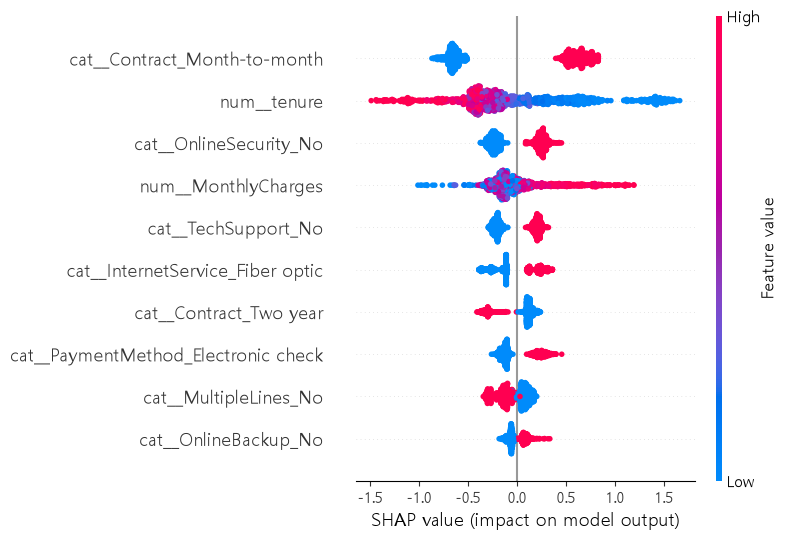

In [13]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test_t.columns)
print("평균 |SHAP| 상위 8개")
print(mean_abs.sort_values(ascending=False).head(8))

shap.summary_plot(shap_values, X_test_t, max_display=10)

> **[판단]** beeswarm 그래프에서 월 단위 계약(`cat__Contract_Month-to-month`)과 가입 기간(`num__tenure`)의 점은 각각 어느 쪽에 모여 있나요? 색(빨강 = 값이 큼)과 함께 읽어, "이 값이 크면 모델은 해지 확률을 올리는가, 내리는가"를 두 피처에 대해 적으세요.
>
> 나의 답: 월 단위 계약 점은 빨강(값 1)이 SHAP 양수 쪽, 즉 해지 확률을 올리는 쪽에 모입니다. 가입 기간은 값이 작을 때(파랑)가 양수 쪽에 모이므로, 가입 기간이 짧으면 해지 확률을 올리고 길면 내립니다.


## 2-4. 어디서 꺾이는가: dependence

**[직접 작성]** 가입 기간과 월 요금의 기여도를 구간별로 평균해 표로 출력하세요.

- 가입 기간 구간: `[0, 6, 12, 24, 48, 72]` (개월)
- 월 요금 구간: `[0, 40, 70, 90, 120]` (달러)

<details><summary>힌트</summary>

```python
tenure_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__tenure")])
tenure_bin = pd.cut(X_test_t["num__tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
tenure_shap.groupby(tenure_bin.values, observed=True).mean()
```
</details>

In [14]:
tenure_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__tenure")])
tenure_bin = pd.cut(X_test_t["num__tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
print("가입 기간 구간별 평균 SHAP")
print(tenure_shap.groupby(tenure_bin.values, observed=True).mean().round(3))

mc_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__MonthlyCharges")])
mc_bin = pd.cut(X_test_t["num__MonthlyCharges"], [0, 40, 70, 90, 120], include_lowest=True)
print("\n월 요금 구간별 평균 SHAP")
print(mc_shap.groupby(mc_bin.values, observed=True).mean().round(3))

가입 기간 구간별 평균 SHAP
(-0.001, 6.0]    0.951
(6.0, 12.0]      0.325
(12.0, 24.0]    -0.027
(24.0, 48.0]    -0.283
(48.0, 72.0]    -0.579
dtype: float64

월 요금 구간별 평균 SHAP
(-0.001, 40.0]   -0.164
(40.0, 70.0]     -0.143
(70.0, 90.0]     -0.049
(90.0, 120.0]     0.459
dtype: float64


num__tenure 구간별 평균 SHAP:
(-0.001, 6.0]    0.9506
(6.0, 12.0]      0.3255
(12.0, 24.0]    -0.0265
(24.0, 48.0]    -0.2825
(48.0, 72.0]    -0.5788
dtype: float64

num__MonthlyCharges 구간별 평균 SHAP:
(-0.001, 40.0]   -0.1638
(40.0, 70.0]     -0.1427
(70.0, 90.0]     -0.0490
(90.0, 120.0]     0.4593
dtype: float64



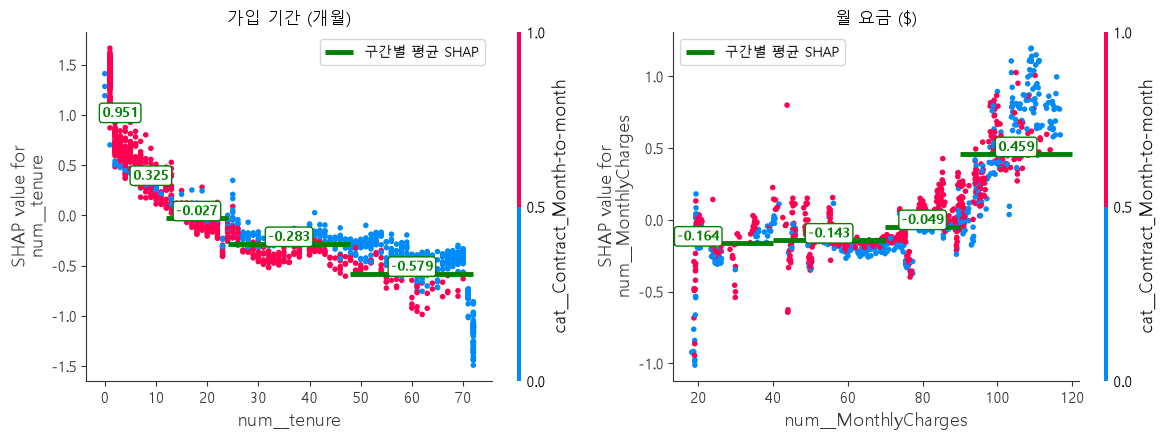

In [25]:
# [추가] 2-4 결과(구간별 평균 SHAP)를 구간 범위의 초록 수평선 + 숫자로 표시
def bin_mean_hlines(ax, feat, edges):
    s = pd.Series(shap_values[:, list(X_test_t.columns).index(feat)], index=X_test_t.index)
    b = pd.cut(X_test_t[feat], edges, include_lowest=True)
    m = s.groupby(b.values, observed=True).mean()             # 구간별 평균 SHAP
    print(feat, "구간별 평균 SHAP:"); print(m.round(4)); print()
    lefts = [iv.left for iv in m.index]
    rights = [iv.right for iv in m.index]
    ax.hlines(m.values, lefts, rights, colors="green", lw=3.5, label="구간별 평균 SHAP")
    for l, r, v in zip(lefts, rights, m.values):
        ax.text((l + r) / 2, v, f"{v:.3f}", ha="center", va="bottom", color="green",
                fontsize=10, fontweight="bold",
                bbox=dict(facecolor="white", edgecolor="green", boxstyle="round,pad=0.2"))
    ax.legend(loc="best")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
shap.dependence_plot("num__tenure", shap_values, X_test_t, ax=axes[0], show=False)
bin_mean_hlines(axes[0], "num__tenure", [0, 6, 12, 24, 48, 72])
shap.dependence_plot("num__MonthlyCharges", shap_values, X_test_t, ax=axes[1], show=False)
bin_mean_hlines(axes[1], "num__MonthlyCharges", [0, 40, 70, 90, 120])
axes[0].set_title("가입 기간 (개월)")
axes[1].set_title("월 요금 ($)")
plt.tight_layout()
plt.show()


> **[판단]** 가입 기간의 기여도는 어느 구간에서 가장 크고, 어디쯤에서 0을 지나나요? 월 요금은 "높을수록 해지"라고 말할 수 있나요, 아니면 특정 금액 위에서만 그런가요? 이 결과를 CS팀에 어떤 행동 지침으로 전하겠습니까?
>
> 나의 답: 가입 기간 기여도는 0~6개월에서 +0.95로 가장 크고, 12~24개월 사이에서 0을 지납니다. 월 요금은 '높을수록 해지'라고 말할 수 없습니다. 40달러 이하와 40~70달러 구간은 음수이고, 90달러 이상에서만 +0.46으로 뛰어오릅니다. CS팀 지침: 가입 1년 이내 고객, 특히 월 요금 90달러 이상인 고객을 먼저 챙기기.


## 2-5. 고객 한 명: waterfall

**[직접 작성]** 평가용 고객 중 모델이 해지 확률을 **가장 높게** 매긴 고객을 찾아, 그 고객의 해지 확률과 가입 기간·계약·월 요금을 출력하고, waterfall 그래프를 그리세요.

<details><summary>힌트</summary>

```python
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
shap.plots.waterfall(shap.Explanation(values=shap_values[i], base_values=base_value,
                                      data=X_test_t.iloc[i], feature_names=list(X_test_t.columns)))
```
</details>

가장 높은 해지 확률: 0.9169
tenure                         1
Contract          Month-to-month
MonthlyCharges              95.1
Name: 3380, dtype: object


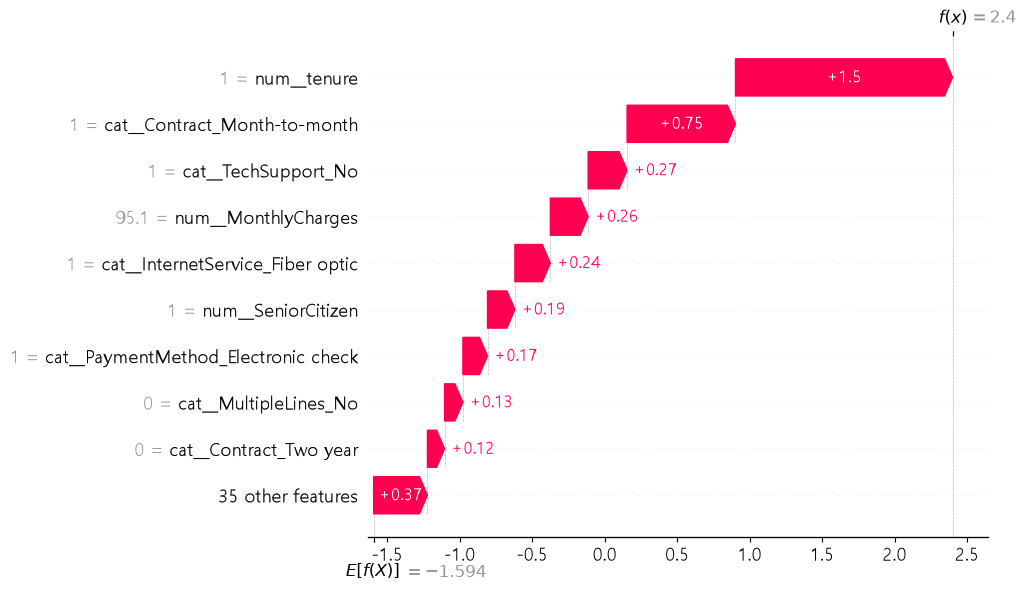

In [15]:
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
print("가장 높은 해지 확률:", round(prob[i], 4))
print(test_df.iloc[i][["tenure", "Contract", "MonthlyCharges"]])

shap.plots.waterfall(shap.Explanation(values=shap_values[i], base_values=base_value,
                                      data=X_test_t.iloc[i], feature_names=list(X_test_t.columns)))

> **[판단]** 이 고객에게 전화할 CS팀 상담원에게, 이 그래프를 한 문장으로 바꿔 전해 보세요. 그 문장에 "이것을 바꾸면 해지하지 않는다"는 뜻이 들어가지 않도록 주의하세요.
>
> 나의 답: '이 고객은 가입한 지 1개월이고 월 단위 계약이라 해지 위험 신호가 강합니다(해지 확률 92%). 가입 기간은 바꿀 수 없으니, 계약 전환을 제안해 볼 만합니다.' 이 문장에 '계약을 바꾸면 해지하지 않는다'는 뜻이 들어가지 않도록 하고, 전환 제안은 실험으로 확인해야 한다는 조건을 붙입니다.


---
# Part 3. SHAP을 읽을 때의 함정

## 3-1. 상관 피처가 기여도를 나눠 가진다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 월 요금과 광케이블 인터넷은 정보가 많이 겹치는 피처입니다(광케이블 요금이 비쌈).

> **[판단]** 예상: 월 요금을 모델에서 빼고 다시 학습하면, 광케이블 인터넷(`cat__InternetService_Fiber optic`)의 기여도 절댓값 평균은 지금(2-3)보다 커질까요, 작아질까요, 그대로일까요?
>
> 나의 답: 예상 적중: 커질 것이라고 예상했고, 실제로 광케이블의 평균 기여도가 0.199에서 0.391로 두 배 가까이 커졌습니다.


**[직접 작성]** 다음을 계산해 출력하세요.

1. 평가용 데이터에서 월 요금과 "광케이블 여부(0/1)"의 상관계수
2. 현재 모델에서 두 피처의 기여도 절댓값 평균, 그리고 고객마다 두 기여도를 **더한 뒤** 절댓값의 평균
3. 월 요금을 뺀 피처로 경사 부스팅을 다시 학습했을 때, 광케이블의 기여도 절댓값 평균과 평가용 AUC

<details><summary>힌트</summary>

3번은 `num_cols`에서 월 요금을 뺀 전처리를 새로 만들어야 합니다. 이 셀 안에서 `ColumnTransformer`를 직접 만들고, `TreeExplainer`도 새 모델로 다시 만듭니다.
</details>

In [16]:
cols = list(X_test_t.columns)
mc, fi = cols.index("num__MonthlyCharges"), cols.index("cat__InternetService_Fiber optic")
corr = np.corrcoef(test_df["MonthlyCharges"], (test_df["InternetService"] == "Fiber optic").astype(int))[0, 1]
print("월 요금 vs 광케이블 상관계수:", round(corr, 3))
print("평균 |SHAP| 월 요금:", round(np.abs(shap_values[:, mc]).mean(), 4), "| 광케이블:", round(np.abs(shap_values[:, fi]).mean(), 4))
print("두 기여도를 더한 뒤 절댓값 평균:", round(np.abs(shap_values[:, mc] + shap_values[:, fi]).mean(), 4))

# 월 요금을 뺀 피처로 다시 학습
num2 = ["tenure", "SeniorCitizen"]
pre2 = ColumnTransformer([("num", "passthrough", num2),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
X2_tr = pd.DataFrame(pre2.fit_transform(train_df[features]), columns=pre2.get_feature_names_out())
X2_te = pd.DataFrame(pre2.transform(test_df[features]), columns=pre2.get_feature_names_out())
gb2 = GradientBoostingClassifier(random_state=42).fit(X2_tr, y_train)
sv2 = shap.TreeExplainer(gb2).shap_values(X2_te)
fi2 = list(X2_te.columns).index("cat__InternetService_Fiber optic")
print("\n월 요금 제외 후 광케이블 평균 |SHAP|:", round(np.abs(sv2[:, fi2]).mean(), 4))
print("월 요금 제외 후 평가용 AUC:", round(roc_auc_score(y_test, gb2.predict_proba(X2_te)[:, 1]), 3))

월 요금 vs 광케이블 상관계수: 0.785
평균 |SHAP| 월 요금: 0.2259 | 광케이블: 0.1987
두 기여도를 더한 뒤 절댓값 평균: 0.3853

월 요금 제외 후 광케이블 평균 |SHAP|: 0.3906
월 요금 제외 후 평가용 AUC: 0.847


> **[판단]** 예상은 맞았나요? 월 요금을 뺐을 때 광케이블의 기여도와 AUC가 어떻게 변했는지로, "해지 요인은 월 요금인가, 광케이블인가"라는 질문에 SHAP이 답할 수 있는지 판단하세요. 보고서에는 두 피처를 어떻게 적겠습니까?
>
> 나의 답: 예상은 맞았습니다. 월 요금을 빼면 광케이블 기여도가 두 배가 되고 AUC는 0.843에서 0.847로 약간 올라갑니다. 기여도는 상관된 피처 사이에서 나눠 가지므로 SHAP만으로는 '해지 요인이 월 요금인가, 광케이블인가'에 답할 수 없습니다. 보고서에는 두 피처를 '함께 움직이는 요금·서비스 묶음'으로 적겠습니다.


## 3-2. 단위는 로그 오즈

**[제공]** 같은 기여도(+1.0)가 출발 확률에 따라 확률을 얼마나 바꾸는지 계산합니다.

In [17]:
# [제공] 같은 기여도 +1.0, 다른 확률 변화
sigmoid = lambda z: 1 / (1 + np.exp(-z))
rows = []
for z in [-3, -2, -1, 0, 1]:
    rows.append({"출발 로그 오즈": z, "출발 확률": round(sigmoid(z), 3),
                 "+1.0 뒤의 확률": round(sigmoid(z + 1), 3), "확률 변화 (%p)": round((sigmoid(z + 1) - sigmoid(z)) * 100, 1)})
pd.DataFrame(rows)

,출발 로그 오즈,출발 확률,+1.0 뒤의 확률,확률 변화 (%p)
0,-3,0.047,0.119,7.2
1,-2,0.119,0.269,15.0
2,-1,0.269,0.500,23.1
3,0,0.500,0.731,23.1
4,1,0.731,0.881,15.0


> **[판단]** 어떤 보고서에 "월 단위 계약은 해지 확률을 평균 25%p 올린다"고 적혀 있습니다. 위 표를 근거로 이 문장의 문제를 설명하고, 같은 내용을 정직하게 바꿔 써 보세요.
>
> 나의 답: 표를 보면 +1.0 로그 오즈 변화는 기준 확률에 따라 약 7~23%p입니다. 최대도 약 23%p이므로 '평균 25%p'는 로그 오즈 단위를 확률로 잘못 옮긴 것입니다. 정직한 표현: '로그 오즈로 약 1.0 증가하며, 확률로는 고객 상태에 따라 약 7~23%p 증가한다.'


## 3-3. 보고서 문장 판별하기

다음 문장들이 Part 2의 SHAP 결과로 **쓸 수 있는 문장인지** 판단하세요. 쓸 수 없다면 어떤 함정(인과, 로그 오즈 단위, 상관 피처, 틀린 모델)에 걸렸는지 적습니다.

1. "모델은 월 단위 계약, 짧은 가입 기간, 온라인 보안 미가입을 해지 위험의 주요 신호로 사용한다."
2. "월 단위 고객을 2년 계약으로 전환시키면 해지가 줄어든다."
3. "해지 요인은 월 요금이 아니라 인터넷 종류다."
4. "가입 6개월 이내 고객의 해지 위험이 가장 높다."
5. "온라인 보안 서비스를 무료로 제공해 해지가 줄어드는지, 일부 고객에게 무작위로 시범 적용해 확인할 것을 제안한다."

> **[판단]** 1~5번 각각: 쓸 수 있다 / 쓸 수 없다(걸린 함정)
>
> 나의 답:
>
> 1. 쓸 수 있다. 모델이 쓰는 신호라는 표현입니다.
> 2. 쓸 수 없다 (인과). 관측 데이터로는 계약 전환의 효과를 말할 수 없습니다.
> 3. 쓸 수 없다 (상관 피처). 월 요금과 광케이블은 기여도를 나눠 가집니다.
> 4. 조건부로 쓸 수 있다. '모델 기준'이라고 써야 합니다.
> 5. 쓸 수 있다. 다만 SHAP으로 증명된 결과가 아니라 실험을 제안하는 문장입니다.


---
# Part 4. 경영진과 CS팀에 보고하기

## 4-1. CS팀용 고객별 위험 신호

**[직접 작성]** 평가용 고객 중 해지 확률 상위 10명을 골라, 고객마다 **해지 확률을 가장 많이 올린 피처 3개**(기여도가 큰 양수 순)를 표로 만드세요. 표에는 고객 ID, 해지 확률, 위험 신호 1~3(피처 이름과 기여도)을 넣습니다.

<details><summary>힌트</summary>

```python
top10 = np.argsort(-prob)[:10]
s = pd.Series(shap_values[i], index=X_test_t.columns).sort_values(ascending=False).head(3)
```
</details>

In [18]:
top10 = np.argsort(-prob)[:10]
rows = []
for i in top10:
    sr = pd.Series(shap_values[i], index=X_test_t.columns).sort_values(ascending=False).head(3)
    row = {"고객 idx": i, "customerID": test_df.iloc[i]["customerID"], "해지확률": round(prob[i], 3)}
    for k, (name, val) in enumerate(sr.items(), start=1):
        row[f"위험 신호 {k}"] = f"{name} ({val:+.2f})"
    rows.append(row)
pd.DataFrame(rows)

,고객 idx,customerID,해지확률,위험 신호 1,위험 신호 2,위험 신호 3
0,1090,5178-LMXOP,0.917,num__tenure (+1.50),cat__Contract_Month-to-month (+0.75),cat__TechSupport_No (+0.27)
1,1109,1069-XAIEM,0.910,num__tenure (+1.49),cat__Contract_Month-to-month (+0.78),cat__TechSupport_No (+0.26)
2,1221,0295-PPHDO,0.910,num__tenure (+1.37),cat__Contract_Month-to-month (+0.75),num__MonthlyCharges (+0.28)
3,1175,6861-XWTWQ,0.899,num__MonthlyCharges (+0.73),cat__Contract_Month-to-month (+0.72),num__tenure (+0.63)
4,83,0970-ETWGE,0.896,num__tenure (+1.52),cat__Contract_Month-to-month (+0.77),num__MonthlyCharges (+0.32)
5,344,6230-BSUXY,0.889,num__tenure (+1.59),cat__Contract_Month-to-month (+0.77),cat__TechSupport_No (+0.25)
6,647,6023-YEBUP,0.887,num__tenure (+0.79),cat__Contract_Month-to-month (+0.71),num__MonthlyCharges (+0.59)
7,952,1628-BIZYP,0.872,num__tenure (+1.48),cat__Contract_Month-to-month (+0.77),cat__InternetService_Fiber optic (+0.26)
8,1188,0655-RBDUG,0.871,num__MonthlyCharges (+0.79),num__tenure (+0.74),cat__Contract_Month-to-month (+0.72)
9,618,9248-OJYKK,0.869,num__tenure (+1.46),cat__Contract_Month-to-month (+0.83),cat__TechSupport_No (+0.26)


> **[판단]** 이 표를 상담원이 그대로 쓰기에는 무엇이 불편한가요? (예: 열 이름, 숫자의 단위) 상담원용으로 바꾼다면 위험 신호 열을 어떤 말로 바꾸겠습니까? 한 고객을 골라 예를 들어 보세요.
>
> 나의 답: 불편한 점: 열 이름이 'num__tenure' 같은 내부 이름이고, 기여도 숫자가 로그 오즈 단위라서 상담원이 의미를 알기 어렵습니다. 상담원용 예: '가입 1개월 (해지 신호 +1.50)' → '가입 1개월, 신규 고객'. 'cat__Contract_Month-to-month' → '월 단위 계약'. 'TechSupport_No' → '기술지원 미가입'.


## 4-2. 경영진 보고 메모

분석 결과를 경영기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **모델이 해지 위험 신호로 쓰는 요인 세 가지**: 근거 숫자(순위, 방향, 꺾이는 지점)와 함께
2. **"바꾸면 해지가 줄어든다"고 말할 수 있는 요인의 수**: 몇 개이고 왜 그런지
3. **제안**: 무엇을 어떻게 확인할 것인지 (실험)
4. **주의할 점**: 상관 피처, 모델의 한계(성능이 로지스틱 회귀와 비슷함 등)

> **[판단]** 경영진 보고 메모:
>
> 1. 모델이 쓰는 해지 위험 신호 세 가지:
>
> 2. "바꾸면 해지가 줄어든다"고 말할 수 있는 요인:
>
> 3. 제안:
>
> 4. 주의할 점:
>
> 나의 답:
>
> 1. 해지 위험 신호: 가입 기간이 짧음(특히 12개월 이내), 월 단위 계약, 월 요금 90달러 이상.
> 2. 바꾸면 해지가 줄어든다고 말할 수 있는 요인: 0개. SHAP은 모델이 쓰는 신호만 보여 줍니다. 계약 전환처럼 바꿀 수 있는 요인도 실험 전에는 효과를 말할 수 없습니다.
> 3. 제안: 월 단위 고객 일부에게 1년 계약 전환 혜택을 무작위로 주고, 대조군과 해지율을 비교합니다.
> 4. 주의할 점: 월 요금과 광케이블은 기여도를 나눠 가집니다. 모델 성능은 로지스틱 회귀(0.845)와 거의 같습니다(0.848).


---
# 마무리

## 이 Chapter의 판단 포인트

> **SHAP이 큰 요인은 모델이 많이 쓴 요인이지 해지의 원인이 아니다. "요인을 바꾸면 결과가 바뀌는가"는 실험으로 확인한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "SHAP 결과를 보고서에 옮길 때 '요인'을 '원인'으로 바꿔 쓰지 않았는지 확인한다."

> **[판단]** 나의 체크리스트 8번(더 강한 모델을 고를 때):
>
> 나의 답: 체크리스트 8번(더 강한 모델을 고를 때): fold별 차이가 흔들리면 복잡한 모델을 고르지 않는다. 이번 실습에서 부스팅과 로지스틱 회귀는 차이가 없었습니다.


> **[판단]** 나의 체크리스트 9번(모델 설명을 보고할 때):
>
> 나의 답: 체크리스트 9번(모델 설명을 보고할 때): SHAP 결과를 '원인'이 아니라 '모델이 쓰는 신호'로 적는다. 바꿀 수 있는 요인은 실험으로 확인한 뒤에 효과를 말한다.


## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 6부터는 정답이 없는 데이터를 다루는 비지도학습입니다. 고객을 묶고, 그 묶음을 의심하는 법을 배웁니다.